In [1]:
import os
import sys

# Run from the project root so `src` imports and relative data paths resolve.
if os.path.basename(os.getcwd()) == "jupyter_notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import torch 
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.true_constitutive_law import KinematicHardeningPlasticity
from src.ou_trajectories import generate_ou_trajectories, smooth_ou_trajectories
import src.true_constitutive_law as tcl
from src.neural_variational_ode import Dissipation, Energy, VariationalODESolver
from src.ou_trajectories import generate_ou_trajectories
from torch.utils.data import TensorDataset, DataLoader


In [3]:
params = {'font.family': 'serif',
          'font.sans-serif': 'Times New Roman',
          'font.size': 14,
          'lines.linewidth': 2,
          'text.usetex': False,
          'xtick.top': True,
          'xtick.minor.visible': True,
          'ytick.minor.visible': True,
          'xtick.direction': 'in',
          'xtick.major.top': True,
          'xtick.major.bottom': True,
          'xtick.minor.top': True,
          'xtick.minor.bottom': True,
          'xtick.minor.width': 1,
          'xtick.major.width': 1,
          'xtick.minor.size': 3, 
          'xtick.major.size': 6,
          'ytick.right': True,
          'ytick.direction': 'in',
          'ytick.major.left': True,
          'ytick.major.right': True,
          'ytick.minor.left': True,
          'ytick.minor.right': True,
          'ytick.minor.width': 1,
          'ytick.major.width': 1,
          'ytick.minor.size': 3,
          'ytick.major.size': 6,
          'legend.frameon': False,
          'lines.markersize': 4.0,
          'axes.formatter.use_mathtext': True,
          'text.latex.preamble' : r'\usepackage{amsmath}',
          'text.usetex': True}
plt.rcParams.update(params)

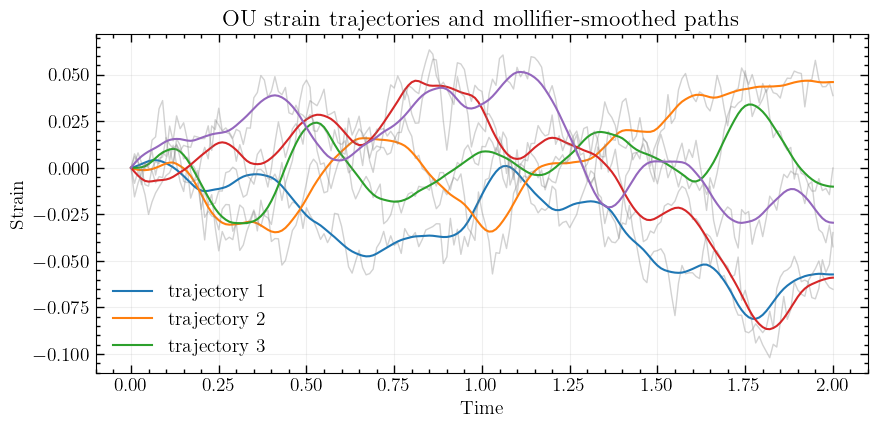

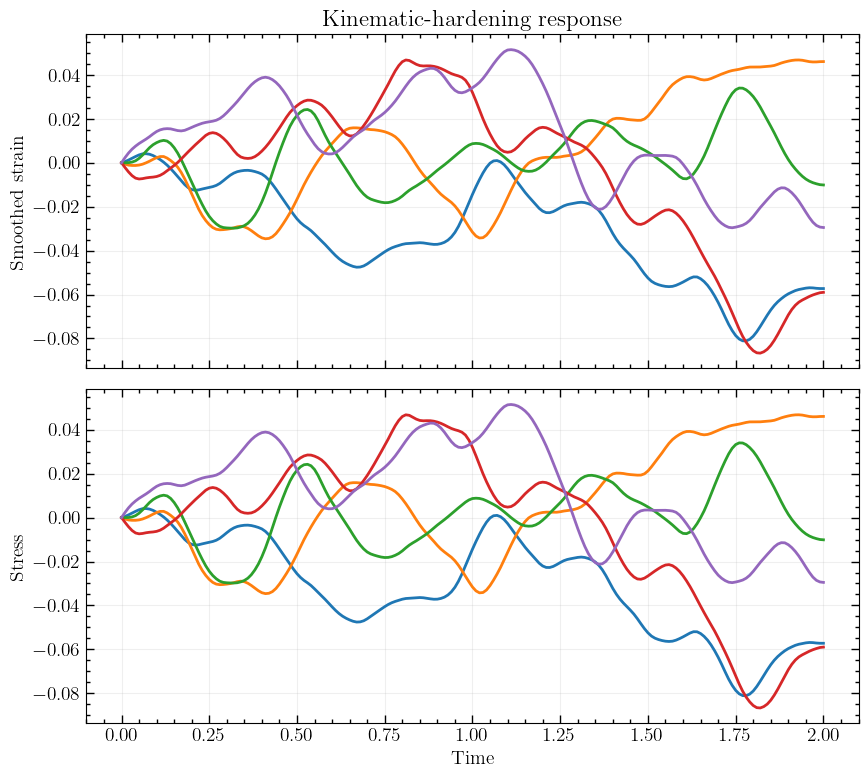

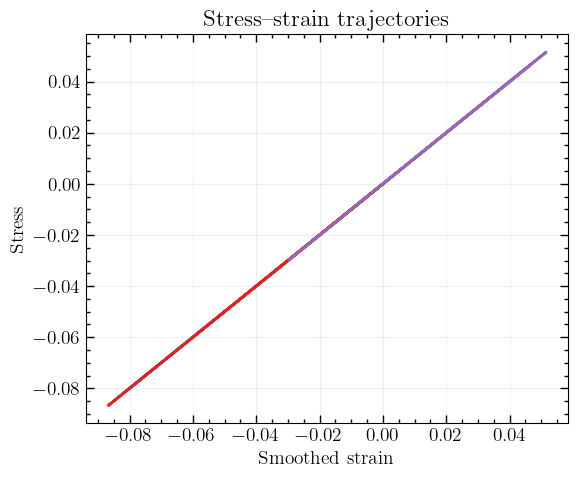

In [4]:
# 1. Sample strain trajectories with an OU process.
n_trajectories = 64
T = 2.0
dt = 1.0 / 100.0
theta = 3.0
mu = 0.0
sigma = 0.08
x0 = 0.0

# 2. Smooth the sampled strain using the mollifier convolution.
mollifier_window = 21
times, strain_trajectories = generate_ou_trajectories(
    theta=theta,
    mu=mu,
    sigma=sigma,
    x0=x0,
    n_trajectories=n_trajectories,
    T=T,
    dt=dt,
    seed=42,
)
strain_trajectories_smooth = smooth_ou_trajectories(
    strain_trajectories,
    window_size=mollifier_window,
)

# 3. Visualize a few raw and smoothed strain trajectories.
fig, ax = plt.subplots(figsize=(9, 4.5))
for trajectory_index in range(min(5, n_trajectories)):
    ax.plot(
        times,
        strain_trajectories[trajectory_index],
        color="tab:gray",
        alpha=0.35,
        linewidth=1.0,
    )
    ax.plot(
        times,
        strain_trajectories_smooth[trajectory_index],
        linewidth=1.5,
        label=f"trajectory {trajectory_index + 1}" if trajectory_index < 3 else None,
    )
ax.set_xlabel("Time")
ax.set_ylabel("Strain")
ax.set_title("OU strain trajectories and mollifier-smoothed paths")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 4. Solve for stress with the kinematic-hardening model.
E = 1.0
H = 1.0
sigma_y = 1
rate_exponent = 0.3
kinematic_model = KinematicHardeningPlasticity(
    node_count=1,
    model_dt=dt,
    m=rate_exponent,
    E=E,
    H=H,
    sigma_y=sigma_y,
)

stress_trajectories = np.empty_like(strain_trajectories_smooth)
plastic_strain_trajectories = np.empty_like(strain_trajectories_smooth)
for trajectory_index, strain_path in enumerate(strain_trajectories_smooth):
    plastic_strain, stress_path = kinematic_model.stress_history(
        strain_path[:, np.newaxis]
    )
    plastic_strain_trajectories[trajectory_index] = plastic_strain[:, 0]
    stress_trajectories[trajectory_index] = stress_path[:, 0]

# 5. Visualize stress and strain histories, and the stress--strain response.
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for trajectory_index in range(min(5, n_trajectories)):
    axes[0].plot(times, strain_trajectories_smooth[trajectory_index])
    axes[1].plot(times, stress_trajectories[trajectory_index])
axes[0].set_ylabel("Smoothed strain")
axes[1].set_ylabel("Stress")
axes[1].set_xlabel("Time")
axes[0].set_title("Kinematic-hardening response")
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for trajectory_index in range(min(5, n_trajectories)):
    ax.plot(
        strain_trajectories_smooth[trajectory_index],
        stress_trajectories[trajectory_index],
    )
ax.set_xlabel("Smoothed strain")
ax.set_ylabel("Stress")
ax.set_title("Stress--strain trajectories")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [40]:
# 6. Learn W and D with dependent stress/strain and time normalization.
strain_tensor = torch.as_tensor(strain_trajectories_smooth, dtype=torch.float32)
plastic_strain_tensor = torch.as_tensor(plastic_strain_trajectories, dtype=torch.float32)
stress_tensor = torch.as_tensor(stress_trajectories, dtype=torch.float32)
# Use 1 x 1 scaling matrices here; the same code extends to vector data.
# Stress and strain scales are dependent through sigma_* = E epsilon_*.
strain_scale = strain_tensor.abs().amax().clamp_min(torch.finfo(strain_tensor.dtype).eps)
E_star = strain_scale.reshape(1, 1)
S_star = (E * strain_scale).reshape(1, 1)
work_scale = S_star.T @ E_star
energy_scale = work_scale.squeeze()
stress_scale = S_star.squeeze()
time_scale = T
# For this one-component notebook, matrix application is scalar division.
normalized_strain = strain_tensor / E_star[0, 0]
normalized_plastic_strain = plastic_strain_tensor / E_star[0, 0]
normalized_stress = stress_tensor / S_star[0, 0]
assert torch.allclose(
    work_scale,
    energy_scale * torch.eye(1, dtype=work_scale.dtype),
    atol=1e-6,
    rtol=1e-6,
)
# Check the work-conjugacy identity on the sampled trajectories.
physical_work = stress_tensor[:, 1:] * (strain_tensor[:, 1:] - strain_tensor[:, :-1])
normalized_work = normalized_stress[:, 1:] * (
    normalized_strain[:, 1:] - normalized_strain[:, :-1]
)
assert torch.allclose(
    physical_work,
    work_scale.squeeze() * normalized_work,
    atol=1e-6,
    rtol=1e-5,
)
normalized_dt = dt / time_scale
training_dataset = TensorDataset(
    normalized_strain,
    normalized_plastic_strain,
    normalized_stress,
)
train_loader = DataLoader(training_dataset, batch_size=16, shuffle=True)

energy_model = Energy(e_dim=1, xi_dim=1, hidden_sizes=(64, 64))
dissipation_model = Dissipation(xi_dim=1, hidden_sizes=(64, 64))
variational_solver = VariationalODESolver(energy_model, dissipation_model)
optimizer = torch.optim.Adam(variational_solver.parameters(), lr=1e-3)
loss_function = torch.nn.MSELoss()
training_losses = []

Training:   0%|          | 0/100 [00:00<?, ?epoch/s]

Epoch   1/100: loss = 7.563829e-04
Epoch   2/100: loss = 6.787600e-04
Epoch   3/100: loss = 6.237578e-04
Epoch   4/100: loss = 5.926905e-04
Epoch   5/100: loss = 5.516844e-04
Epoch   6/100: loss = 5.118320e-04
Epoch   7/100: loss = 4.625490e-04
Epoch   8/100: loss = 4.172892e-04
Epoch   9/100: loss = 3.611376e-04
Epoch  10/100: loss = 3.047909e-04
Epoch  11/100: loss = 2.407166e-04
Epoch  12/100: loss = 1.805132e-04
Epoch  13/100: loss = 1.214204e-04
Epoch  14/100: loss = 8.494691e-05
Epoch  15/100: loss = 4.689264e-05
Epoch  16/100: loss = 3.131227e-05
Epoch  17/100: loss = 1.255257e-05
Epoch  18/100: loss = 5.248787e-06
Epoch  19/100: loss = 4.632917e-06
Epoch  20/100: loss = 5.918711e-06
Epoch  21/100: loss = 5.250443e-06
Epoch  22/100: loss = 3.372008e-06
Epoch  23/100: loss = 2.258796e-06
Epoch  24/100: loss = 1.589940e-06
Epoch  25/100: loss = 7.753091e-07
Epoch  26/100: loss = 5.937084e-07
Epoch  27/100: loss = 5.909006e-07
Epoch  28/100: loss = 4.589909e-07
Epoch  29/100: loss 

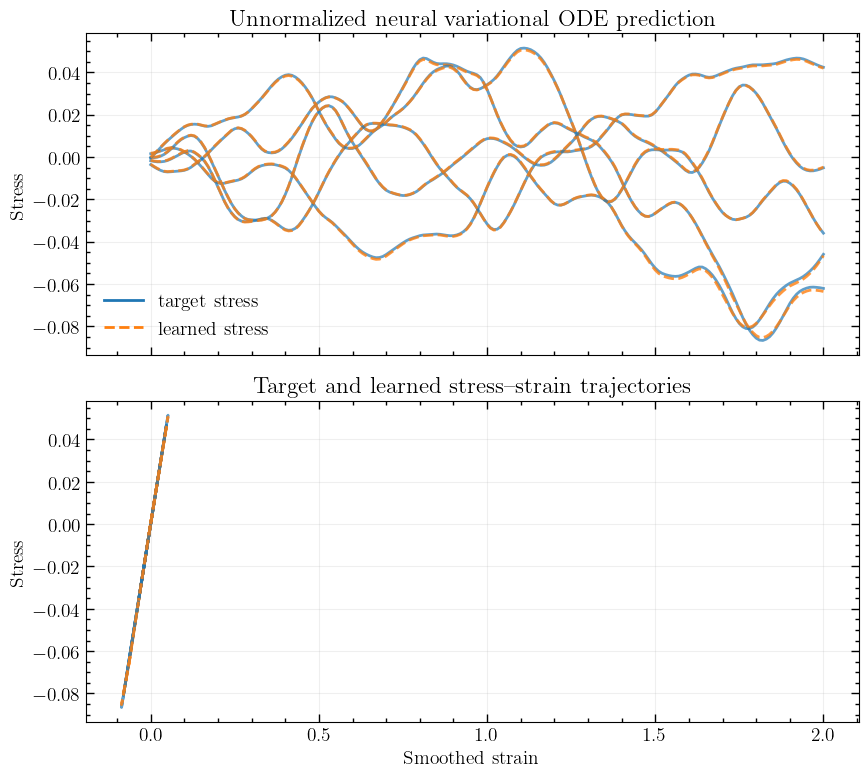

In [41]:

n_epochs = 100
for epoch in tqdm(range(n_epochs), desc="Training", unit="epoch"):
    epoch_loss = 0.0
    for strain_batch, _, stress_batch in train_loader:
        optimizer.zero_grad()
        _, predicted_stress = variational_solver.solve(
            strain_batch,
            dt=normalized_dt,
            create_graph=True,
        )
        loss = loss_function(predicted_stress, stress_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.detach().item() * strain_batch.shape[0]
    epoch_loss /= len(training_dataset)
    training_losses.append(epoch_loss)
    tqdm.write(f"Epoch {epoch + 1:3d}/{n_epochs}: loss = {epoch_loss:.6e}")
variational_solver.eval()

with torch.enable_grad():
    xi_learned, stress_learned = variational_solver.solve(
        normalized_strain,
        dt=normalized_dt,
        create_graph=False,
    )
stress_learned = (stress_learned * S_star.squeeze()).detach().cpu().numpy()

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for trajectory_index in range(min(5, n_trajectories)):
    axes[0].plot(times, stress_trajectories[trajectory_index], color="tab:blue", alpha=0.7)
    axes[0].plot(times, stress_learned[trajectory_index], color="tab:orange", linestyle="--", alpha=0.8)
    axes[1].plot(strain_trajectories_smooth[trajectory_index], stress_trajectories[trajectory_index], color="tab:blue", alpha=0.7)
    axes[1].plot(strain_trajectories_smooth[trajectory_index], stress_learned[trajectory_index], color="tab:orange", linestyle="--", alpha=0.8)
axes[0].plot([], [], color="tab:blue", label="target stress")
axes[0].plot([], [], color="tab:orange", linestyle="--", label="learned stress")
axes[0].set_ylabel("Stress")
axes[0].set_title("Unnormalized neural variational ODE prediction")
axes[0].legend()
axes[1].set_xlabel("Smoothed strain")
axes[1].set_ylabel("Stress")
axes[1].set_title("Target and learned stress--strain trajectories")
for axis in axes:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()
